In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from tensorflow.keras import models
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from tensorflow.keras import models, layers

data_path = '../Data/combined_data_by_year/'

dam = pd.read_parquet(f'{data_path}dam_data_2023_2026.parquet')
rtm = pd.read_parquet(f'{data_path}rtm_data_2023_2026.parquet')
load = pd.read_parquet(f'{data_path}load_data_2023_2026.parquet')
outage = pd.read_parquet(f'{data_path}outage_data_2023_2026.parquet')
solar = pd.read_parquet(f'{data_path}solar_data_2023_2026.parquet')
wind = pd.read_parquet(f'{data_path}wind_data_2023_2026.parquet')

data = pd.merge(dam, rtm, on='interval_end_utc', suffixes=('_dam', '_rtm'))
data = pd.merge(data, load, on='interval_end_utc', suffixes=('', '_load'))
data = pd.merge(data, outage, on='interval_end_utc', suffixes=('', '_outage'))
data = pd.merge(data, solar, on='interval_end_utc', suffixes=('', '_solar'))
data = pd.merge(data, wind, on='interval_end_utc', suffixes=('', '_wind'))

data = data.sort_values('interval_end_utc').reset_index(drop=True)

data.loc[data['lmp_dam'] > 132, 'lmp_dam'] = 132
data.loc[data['lmp_rtm'] > 132, 'lmp_rtm'] = 132

load_forecast = data['load_forecast'].astype(float).values.reshape(-1, 1) 
miso_solar = data['miso'].astype(float).values.reshape(-1, 1)
miso_wind = data['miso_wind'].astype(float).values.reshape(-1, 1)
lmp_dam = data['lmp_dam'].astype(float).values.reshape(-1, 1)
lmp_rtm = data['lmp_rtm'].astype(float).values.reshape(-1, 1) #target/label



c:\Users\atoll\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
window_size = 288

features = np.concatenate((
    lmp_dam,
    load_forecast,
    miso_solar,
    miso_wind
), axis=1)

X = []
y = []
target_dates = []

for i in range(window_size, len(data)):
    X.append(features[i - window_size:i, :])
    y.append(lmp_rtm[i, 0])
    target_dates.append(
        data['interval_end_utc'].iloc[i]
    )

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
    X, y, target_dates, test_size=0.2, shuffle=False
)



In [3]:

scaler_x = MinMaxScaler(feature_range=(0, 1))

scaler_x.fit(X_train.reshape(-1, X_train.shape[2]))

scaled_x_training = scaler_x.transform(
    X_train.reshape(-1, X_train.shape[2])
)

scaled_x_testing = scaler_x.transform(
    X_test.reshape(-1, X_test.shape[2])
)

X_train = scaled_x_training.reshape(
    X_train.shape[0],
    X_train.shape[1],
    X_train.shape[2]
)

X_test = scaled_x_testing.reshape(
    X_test.shape[0],
    X_test.shape[1],
    X_test.shape[2]
)

scaler_y = MinMaxScaler(feature_range=(0, 1))

y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

y_train = scaler_y.fit_transform(y_train)

y_test = scaler_y.transform(y_test)

In [4]:

model = models.Sequential([
    layers.Input((window_size, 4)),
    layers.LSTM(units=32, return_sequences=True),
    layers.Dropout(0.1),
    layers.LSTM(32),
    layers.Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse"
)



early_stopping = EarlyStopping(
    mode="min",
    patience=3,
    min_delta=1e-3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

Epoch 1/20
18642/18642 ━━━━━━━━━━━━━━━━━━━━ 1227s 66ms/step - loss: 0.0051 - val_loss: 0.0150
Epoch 2/20
18642/18642 ━━━━━━━━━━━━━━━━━━━━ 1179s 63ms/step - loss: 0.0046 - val_loss: 0.0150
Epoch 3/20
18642/18642 ━━━━━━━━━━━━━━━━━━━━ 1189s 64ms/step - loss: 0.0044 - val_loss: 0.0159
Epoch 4/20
18642/18642 ━━━━━━━━━━━━━━━━━━━━ 1189s 64ms/step - loss: 0.0042 - val_loss: 0.0161


In [5]:
from sklearn.metrics import r2_score, mean_squared_error

In [6]:
# Get predictions
y_pred = model.predict(X_test)

# Inverse transform predictions
y_pred_original = scaler_y.inverse_transform(
    y_pred.reshape(-1, 1)
)

# Inverse transform actual values
y_test_original = scaler_y.inverse_transform(
    y_test.reshape(-1, 1)
)

# Calculate RMSE in original units
rmse = np.sqrt(mean_squared_error(y_test_original, y_pred_original))

print("Test RMSE:", rmse)

10357/10357 ━━━━━━━━━━━━━━━━━━━━ 157s 15ms/step
Test RMSE: 12.375294468190708


In [7]:
r2 = r2_score(y_test_original, y_pred_original)

print("Test R²:", r2)

Test R²: 0.47557214111467117


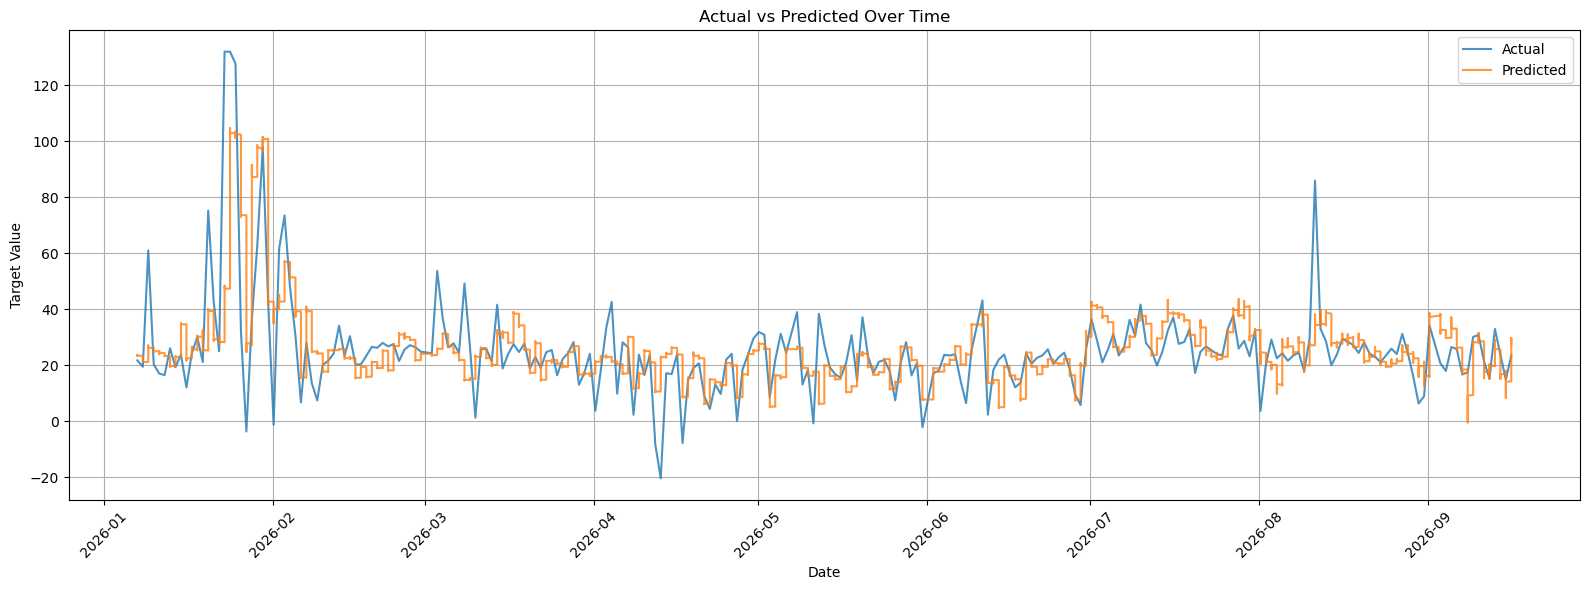

In [8]:
# Convert dates to datetime
dates_test = pd.to_datetime(dates_test)

# Plot
plt.figure(figsize=(16, 6))

plt.plot(dates_test, y_test_original, label='Actual', alpha=0.8)
plt.plot(dates_test, y_pred_original, label='Predicted', alpha=0.8)

plt.title('Actual vs Predicted Over Time')
plt.xlabel('Date')
plt.ylabel('Target Value')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()